# 06 – Thí nghiệm biến đổi log biến mục tiêu

EDA cho thấy `Appliances` lệch phải mạnh (skew 3,39 → 1,19 sau `log1p`). Câu hỏi: huấn luyện trên `log1p(y)`
rồi đổi ngược bằng `expm1` có giúp mô hình dự đoán tốt hơn không?

Dùng `TransformedTargetRegressor`: mô hình học trên log, nhưng `predict` trả về đơn vị Wh → so sánh công bằng.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge

from src.config import RANDOM_STATE
from src.data_loader import load_raw_data
from src.evaluate import regression_metrics
from src.features import make_xy
from src.preprocessing import make_pipeline
from src.split import time_split
from src.train import cv_evaluate, fit_and_validate
from src.visualization import save_fig, set_style

set_style()
train, val, test = time_split(load_raw_data())
X_tr, y_tr = make_xy(train)
X_va, y_va = make_xy(val)
cols = list(X_tr.columns)


def with_log(pipe):
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

## 1. So sánh có / không biến đổi log

In [2]:
def ridge():
    return make_pipeline(Ridge(alpha=100), cols, "linear")


def rf():
    return make_pipeline(RandomForestRegressor(n_estimators=100, min_samples_leaf=50, max_features=0.33,
                                               random_state=RANDOM_STATE, n_jobs=-1), cols, "tree")


experiments = {
    "Ridge": ridge(), "Ridge + log": with_log(ridge()),
    "RF điều chuẩn": rf(), "RF điều chuẩn + log": with_log(rf()),
}
log_results, fitted = {}, {}
for name, model in experiments.items():
    fitted[name], r = fit_and_validate(model, X_tr, y_tr, X_va, y_va)
    r.update(cv_evaluate(model, X_tr, y_tr))
    log_results[name] = r
cols_show = ["cv_RMSE", "cv_MAE", "val_RMSE", "val_MAE", "val_R2", "val_MAPE_%"]
pd.DataFrame(log_results).T[cols_show].round(3)

,cv_RMSE,cv_MAE,val_RMSE,val_MAE,val_R2,val_MAPE_%
Ridge,96.663,57.619,85.597,51.050,0.139,62.761
Ridge + log,96.363,46.596,85.336,40.193,0.144,38.744
RF điều chuẩn,94.031,57.116,84.680,46.652,0.157,51.942
RF điều chuẩn + log,95.451,46.292,85.972,37.446,0.131,33.063


## 2. Sai số theo mức tiêu thụ
Chia các mẫu validation theo mức tiêu thụ thực tế để xem log giúp ở đâu và gây hại ở đâu.

In [3]:
bins = [0, 60, 100, 200, 2000]
labels = ["≤ 60 Wh", "60–100 Wh", "100–200 Wh", "> 200 Wh"]
group = pd.cut(y_va, bins=bins, labels=labels)
rows = {}
for name in ["RF điều chuẩn", "RF điều chuẩn + log"]:
    err = (fitted[name].predict(X_va) - y_va).abs()
    rows[name] = err.groupby(group, observed=False).mean()
by_level = pd.DataFrame(rows)
by_level["số mẫu"] = group.value_counts().reindex(labels)
by_level.round(1)

,RF điều chuẩn,RF điều chuẩn + log,số mẫu
Appliances,,,
≤ 60 Wh,27.4,15.7,1544
60–100 Wh,37.3,19.4,826
100–200 Wh,42.3,31.4,360
> 200 Wh,216.7,257.4,230


Đã lưu hình: reports/figures/06_log_error_by_level.png


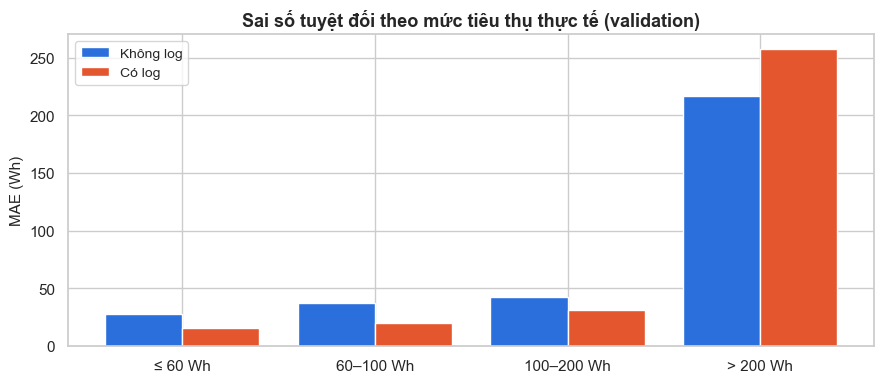

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(labels))
ax.bar(x - 0.2, by_level["RF điều chuẩn"], width=0.4, label="Không log")
ax.bar(x + 0.2, by_level["RF điều chuẩn + log"], width=0.4, label="Có log")
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("MAE (Wh)")
ax.set_title("Sai số tuyệt đối theo mức tiêu thụ thực tế (validation)")
ax.legend()
fig.tight_layout()
save_fig(fig, "06_log_error_by_level")
plt.show()

**Nhận xét:**
- Biến đổi log **giảm mạnh MAE** (RF: ~46,7 → ~37,4 Wh; Ridge: ~51 → ~40 Wh) và MAPE, nhưng **RMSE gần như không
  đổi hoặc tăng nhẹ**.
- Lý do: huấn luyện trên log tương đương tối ưu **sai số tương đối** → mô hình dự đoán rất tốt mức nền (≤ 100 Wh,
  chiếm phần lớn thời gian), nhưng dự đoán **thấp** các đỉnh lớn (> 200 Wh) – nơi RMSE phạt nặng nhất.
- **Đánh đổi:** chọn log nếu mục tiêu là dự đoán đúng mức tiêu thụ thường ngày (MAE); không dùng log nếu cần bắt
  được các đỉnh (RMSE).
- **Quyết định:** nhóm giữ **RMSE là độ đo chính** để chọn mô hình (so sánh được với bài báo), nên mô hình chính
  huấn luyện **không log**; phiên bản có log được báo cáo thêm như một lựa chọn khi ưu tiên MAE.